# Cuadernillo 2 · Análisis exploratorio

**Autor:** Dilan Aldana - Jeison Del Rio

**Objetivo.** Ver cómo se comporta cada variable y cuáles se relacionan con la aprobación, para llegar al modelado sabiendo qué variables prometen.

**Fecha:** 22 de noviembre de 2026

**Desarrollo.** Primero cada variable por separado (univariado), después cada una contra la aprobación (bivariado) y por último varias a la vez (multivariado). Al final, una **conclusión** con las variables que más pesan.

In [1]:
# Python básico
import sys
import warnings
from pathlib import Path

# Datos y gráficos
import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))

from src import analisis

warnings.filterwarnings("ignore")
analisis.configurar_estilo()

print("Todo listo")


Todo listo



**Qué hace esta celda.** Carga los gráficos, las funciones del proyecto y el estilo común. No calcula nada.

## Preparación

Se lee el archivo y se crea `Aprobado`: **1 = aprobado, 0 = rechazado**. Los modelos necesitan números, no letras.

In [2]:
df = pd.read_csv(RAIZ / "data" / "solicitudes_prestamos.csv")
df["Aprobado"] = (df["Loan_Status"] == "Y").astype(int)

print(f"Filas: {len(df)}   Columnas: {df.shape[1]}")
print(df["Aprobado"].value_counts().rename({1: "Aprobado", 0: "Rechazado"}))


Filas: 614   Columnas: 14
Aprobado
Aprobado     422
Rechazado    192
Name: count, dtype: int64



Se mantienen las **614 solicitudes**; `Aprobado` tiene 422 unos y 192 ceros. Con 1 y 0, el promedio de la columna es directamente la tasa de aprobación.

## 1. Análisis de una variable (univariado)

Cada variable por separado, para ver su forma antes de cruzarla con otras.

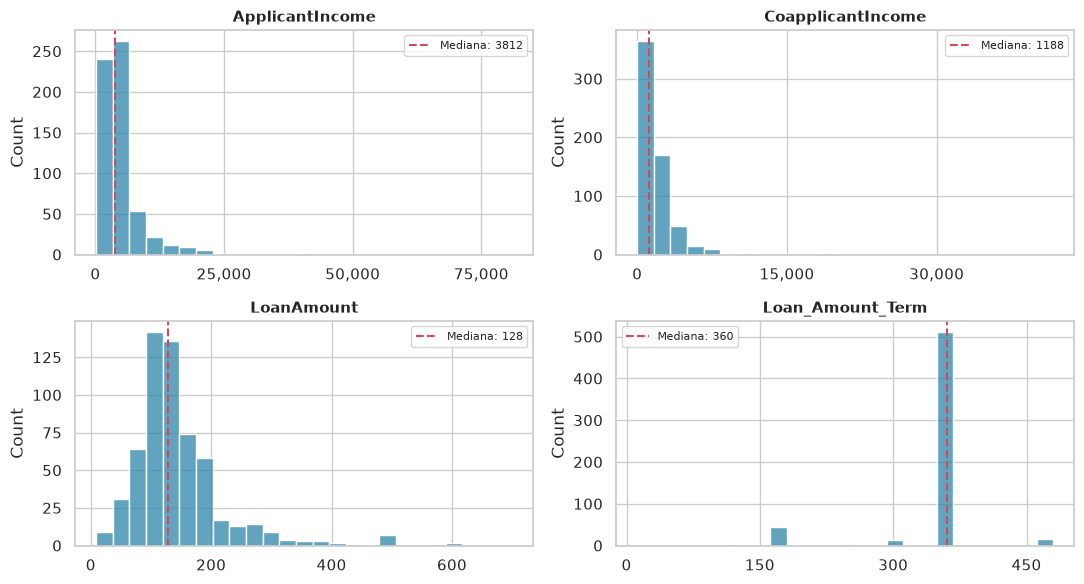

In [3]:
analisis.graficar_numericas(
    df, ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
)

**Variables numéricas.** Los ingresos están **estirados hacia la derecha**: la mediana es 3.812, pero el promedio sube a 5.403 por unos pocos ingresos muy altos (el máximo es 81.000). El **44,5 % no tiene codeudor** y la mitad de los préstamos está entre 100 y 168. El **83,4 % pide 360 meses**: el plazo casi no distingue entre solicitudes.

Por esos valores extremos, las variables se **escalan** antes de entrenar (cuadernillo 4) y los huecos se rellenan con la **mediana** (cuadernillo 3), que no se deja arrastrar por ellos.

### Variables categóricas

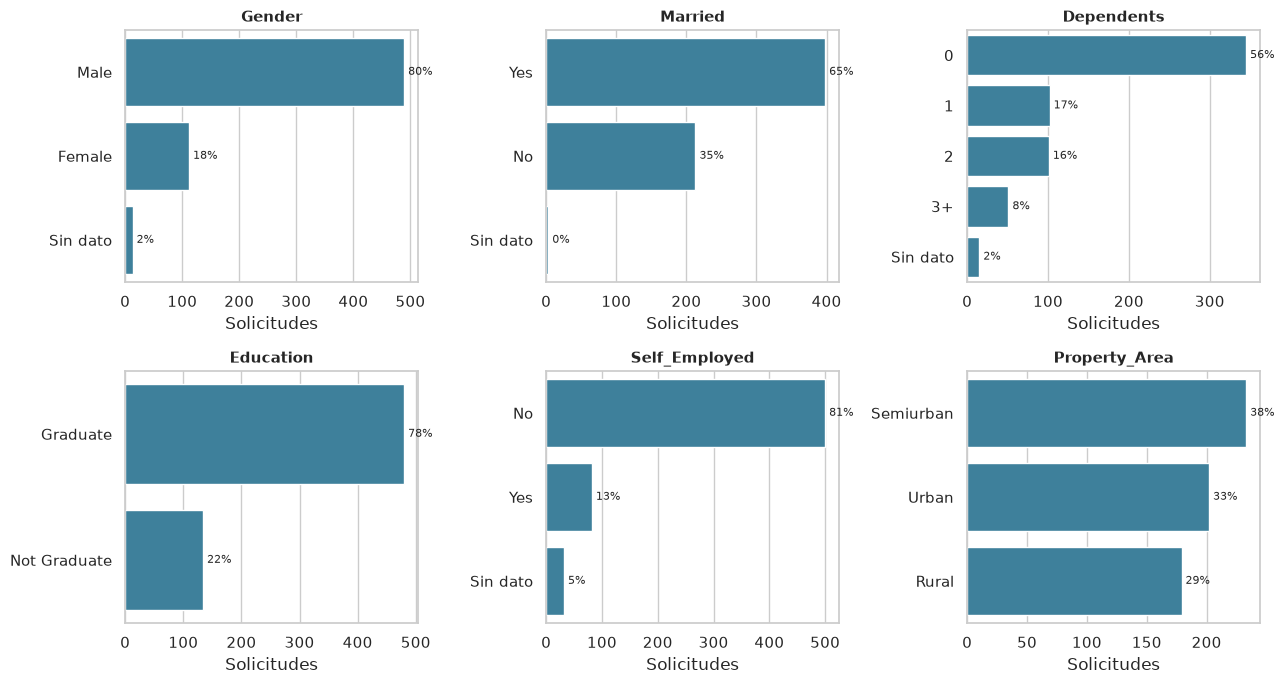

In [4]:
analisis.graficar_categoricas(
    df, ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]
)

Ninguna categoría es demasiado pequeña: género (79,6 % hombres), estado civil (64,8 % casados), dependientes (56,2 % sin dependientes), educación (78,2 % universitarios), empleo (81,4 % asalariados) y zona (37,9 % semiurbana, 32,9 % urbana, 29,2 % rural).

Los casos sin dato (2,1 % en género, 0,5 % en estado civil, 5,2 % en empleo) no se borran: quedan como categoría `"Sin dato"` (cuadernillo 3).

## 2. Análisis de dos variables (bivariado)

Se cruza cada variable con la respuesta: cada barra es la tasa de aprobación de un grupo y la línea roja, el promedio general (68,7 %).


Tasa de aprobación según historial crediticio:
Historial
Con historial    79.6
Sin dato         74.0
Sin historial     7.9
Name: Aprobado, dtype: float64

Tasa de aprobación según zona:
Property_Area
Rural        61.5
Semiurban    76.8
Urban        65.8
Name: Aprobado, dtype: float64



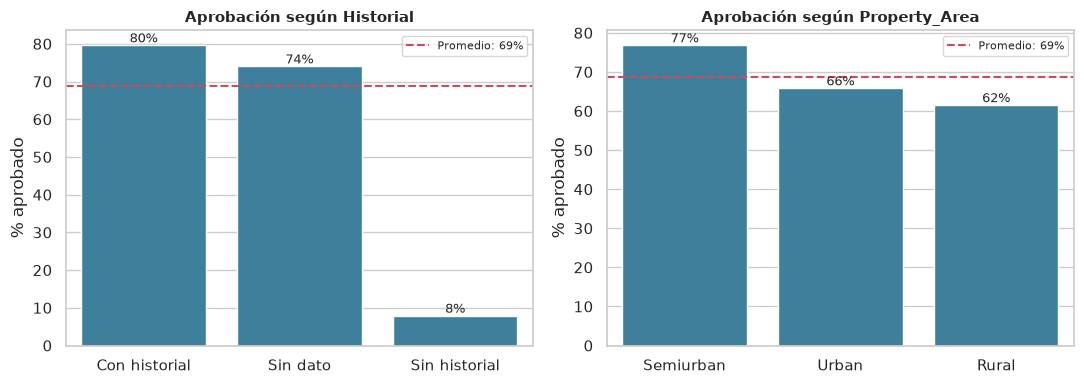

In [5]:
# Una versión con nombres claros solo para los gráficos
df_plot = df.assign(
    Historial=df["Credit_History"].map({0.0: "Sin historial", 1.0: "Con historial"})
                        .fillna("Sin dato")
)

print("Tasa de aprobación según historial crediticio:")
print(analisis.tasa_aprobacion(df_plot, "Historial"))
print()
print("Tasa de aprobación según zona:")
print(analisis.tasa_aprobacion(df, "Property_Area"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
analisis.graficar_tasa_aprobacion(df_plot, "Historial", axes[0])
analisis.graficar_tasa_aprobacion(df, "Property_Area", axes[1])
plt.tight_layout()
plt.show()

**Historial crediticio.** La diferencia es enorme: **con historial se aprueba el 79,6 %; sin historial, solo el 7,9 %**. Las 50 solicitudes sin el dato (`Sin dato`) se aprueban el 74 %, parecido a quienes sí tienen historial; por eso se imputan en lugar de borrarse (cuadernillo 3).

**Zona.** Va de **61,5 % en rural a 76,8 % en semiurbana**: hay diferencia, pero mucho menor. El historial es el primer filtro; la zona ajusta.

## 3. Análisis de varias variables (multivariado)

Varias variables a la vez, para responder dos cosas: si alguna repite información de otra y cómo se combinan el historial y la zona.

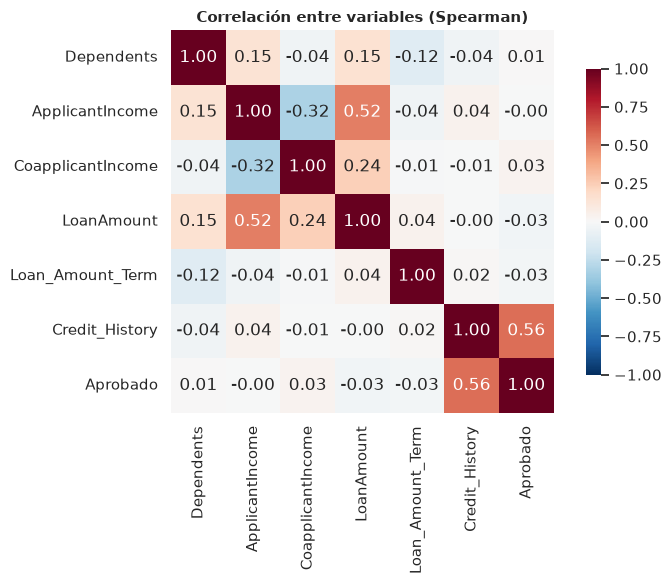


Correlación con la aprobación:
Credit_History       0.56
LoanAmount          -0.03
CoapplicantIncome    0.03
Loan_Amount_Term    -0.03
Dependents           0.01
ApplicantIncome     -0.00
Name: Aprobado, dtype: float64



In [6]:
# Se convierte "3+" solo para poder calcular correlaciones
df_num = df.assign(Dependents=df["Dependents"].replace("3+", "3").astype(float))

columnas_num = ["Dependents", "ApplicantIncome", "CoapplicantIncome",
                "LoanAmount", "Loan_Amount_Term", "Credit_History", "Aprobado"]

correlacion = analisis.graficar_correlacion(df_num, columnas_num)

print("Correlación con la aprobación:")
print(correlacion["Aprobado"].drop("Aprobado").sort_values(key=abs, ascending=False).round(2))

**Mapa de correlaciones.** Cada celda es un número entre −1 y 1 que mide si dos variables se mueven juntas: cerca de 1, suben a la vez; cerca de −1, una sube cuando la otra baja; cerca de 0, no hay relación lineal. El rojo indica relación positiva, el azul negativa y el blanco ausencia de relación. La última fila y la última columna son las que importan, porque cruzan todo con `Aprobado`.

- Solo **`Credit_History` (0,56)** se acerca de forma clara a la aprobación. Las demás quedan entre −0,03 y 0,03.
- Entre predictoras, la relación más alta es **ingreso ↔ monto (0,68)**: quien gana más suele pedir más. No llega a 0,8, así que no son dos copias y no hay que eliminar ninguna.

Que una variable tenga correlación baja no la vuelve inútil: solo dice que, sola, no acompaña de forma lineal a la aprobación.

In [7]:
print("Aprobación combinando zona e historial crediticio:")

tabla_cruzada = pd.crosstab(
    df["Property_Area"], df["Credit_History"],
    values=df["Aprobado"], aggfunc="mean",
).round(2)
tabla_cruzada.columns = ["Sin historial", "Con historial"]
tabla_cruzada


Aprobación combinando zona e historial crediticio:



,Sin historial,Con historial
Property_Area,,
Rural,0.07,0.72
Semiurban,0.13,0.88
Urban,0.03,0.77


**Zona + historial.** Con historial, la aprobación va de **72 % (rural) a 88 % (semiurbana)**. Sin historial, ninguna zona supera el **13 %**. La zona solo marca diferencias cuando ya hay historial: el historial decide si hay conversación y la zona ajusta el resultado.

## 4. Conclusión

- **`Credit_History` es la variable decisiva:** 79,6 % de aprobación con historial frente a 7,9 % sin historial, y la única correlación alta con la respuesta (0,56).
- **La zona ajusta, no decide:** importa solo cuando ya hay historial (72 % a 88 %); sin historial, ninguna zona pasa del 13 %.
- **Los ingresos están estirados y el plazo es casi constante** (83,4 % a 30 años): aportan poco y hay que escalarlos (cuadernillo 4).
- **No hay variables redundantes:** la relación más alta entre predictoras es 0,68 y no obliga a eliminar ninguna.

Se espera que un modelo sencillo apoyado en el historial funcione bien. Se comprueba en el cuadernillo 4.